# Fresh runs: which results hold?

So far every number for the chemical plant (Tennessee Eastman) came from one small set of files: 21 test runs, one per fault, made by the Braatz lab. Two of those numbers needed checking.

1. **The straight-link residual detector caught 81% of fault moments**, the best of the eight simple detectors. But its settings were chosen after looking at those same 21 runs, so the 81% could be flattering.
2. **The CUSUM chart caught 40% of fault 3**, a fault every other detector misses. With one run per fault, that could be one lucky run.

This notebook repeats the scoring on **1,000 runs the detectors have never seen**. No detector setting was changed for it.

Along the way the fresh runs showed a flaw in how detectors were being judged on this plant. Section 3 explains the flaw and the fix, and every later table uses the fix.

The first run downloads about 910 MB and takes about 45 minutes. Results are saved in `results/cache/`, so later runs take seconds.

**Words used here** (the rest are in `main.ipynb`)
- **Alarm line**: the score above which a detector raises an alarm.
- **Catch rate**: the share of fault moments above the alarm line, when the line is placed to allow 1 false alarm in 100.
- **Plausible range**: where a number could land with different data. Every range here is a 90% range from *resampling*: redrawing the data many times and recomputing the number.
- **Fresh run**: a run that played no part in choosing any setting.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import data, explore, plots, run, structure

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 60)

tep = data.load("tep")                                               # the Braatz files used so far
fresh, twins = data.load("tep_rieth"), data.load("tep_rieth_control")
fresh_1, twins_1 = data.load_tep_rieth(fit_runs=1), data.load_tep_rieth_control(fit_runs=1)
print(f"{len(fresh.runs)} fresh fault runs, {len(twins.runs)} twins with no fault, "
      f"{len(fresh.calibration_runs())} separate fault-free runs for setting alarm lines; "
      f"detectors learn from {len(fresh.runs[0].fit):,} normal readings")

1000 fresh fault runs, 50 twins with no fault, 50 separate fault-free runs for setting alarm lines; detectors learn from 10,000 normal readings


## 1. The fresh runs

In 2017 Rieth and colleagues ran the same plant model 500 times for each fault, each time with different random numbers, and published the results. Their files cover faults 1 to 20 (fault 21 is not in them). We use:

| What | Which runs | Size |
|---|---|---|
| Runs to score | runs 1-50 of each of the 20 faults | 1,000 runs of 48 hours; the fault starts after 8 hours |
| Normal data the detectors learn from | fault-free training runs 1-20 | 10,000 readings (the Braatz files gave 500) |
| Twins: the scored runs with no fault | fault-free testing runs 1-50 | 50 runs of 48 hours |
| Separate fault-free runs, for setting alarm lines | fault-free testing runs 51-100 | 50 runs of 48 hours |

Which runs to use was fixed by their numbers before anything was scored. A test checks that none of them repeats a Braatz file.

**Twins.** These files have a property we found by looking at the data. Run number 7 uses the same random numbers whether it has fault 1, fault 12 or no fault at all. So every faulty run has a fault-free **twin**: identical until the moment the fault starts, and from then on showing what the same run would have done with no fault.

The twins let us read the start of the fault off the data instead of trusting the description. For each fault, the table shows the first reading at which the faulty runs differ from their twins. Readings are counted from 0, so index 160 is the 161st reading, 8 hours in.

In [2]:
data.rieth_onset_check()

,earliest first difference,latest first difference,runs that differ at index 160,runs
fault,,,,
01 step: A/C feed ratio,160,160,50,50
02 step: B composition,160,160,50,50
03 step: D feed temperature,160,160,50,50
04 step: reactor cooling water temp,160,160,50,50
05 step: condenser cooling water temp,160,160,50,50
06 step: A feed loss,160,160,50,50
07 step: C header pressure loss,160,160,50,50
"08 random: A, B, C feed composition",160,172,2,50
09 random: D feed temperature,160,172,2,50


**Reading this**
- **No run differs from its twin before index 160.** In the ten faults that switch on as a sudden step, all 50 runs differ at exactly index 160. So the fault starts 8 hours in, the same as in the Braatz files.
- The other ten faults are disturbances that build up gradually. In some runs it takes a while before any reading changes at all: up to 83 readings (about 4 hours) for fault 18. We still count the fault from index 160, as the files' authors do, so for these faults a small part of what is labelled "fault" has nothing to detect yet.

Two more consequences of the twins are used below:
- The first 8 hours of run 7 are the same readings for all 20 faults. So the 1,000 runs hold only 50 different stretches of normal data, not 1,000.
- Fault-free runs used to set alarm lines must have run numbers that no scored run has. That is why runs 51-100 are used.

## 2. Score everything

Every detector learns "normal" from the 10,000 normal readings, then scores the 1,000 fresh runs, the 50 twins and the 50 separate fault-free runs.

As a second version, every detector learns from a single run of 500 readings, which is how much the Braatz files gave it. Two things changed at once between the Braatz setup and this one: the runs are fresh, and there is 20 times more normal data to learn from. The second version separates the two.

**No setting was changed.** These are the settings from `main.ipynb`:

In [3]:
run.score_all(datasets=[fresh, twins, fresh.matched_from, fresh_1, twins_1, fresh_1.matched_from], verbose=False)
pd.Series(run.METHODS, name="settings (unchanged)").to_frame()

,settings (unchanged)
rolling_z,{'window': 5}
ewma,{'lam': 0.2}
cusum,{'k': 0.5}
pca,{'var': 0.9}
iforest,"{'window': 10, 'n_estimators': 100}"
matrix_profile,{'m': 16}
link_straight,{'window': 5}
link_curved,{'window': 5}


## 3. A flaw in the alarm line, and the fix

**The old rule.** Until now, each detector's alarm line was placed using the normal part of the scored runs themselves: the line sits where 1 in 100 of those normal readings crosses it. In this plant the normal part of a run is its *first 8 hours*, and the fault part is the *40 hours after that*.

**The flaw.** That rule assumes a healthy plant looks the same in hours 8-48 as in hours 0-8. If a detector's score tends to be higher later in a run even when nothing is wrong, an alarm line set on the first 8 hours is too low for the rest of the run. The detector then rings in hours 8-48 whether or not there is a fault, and all of that ringing is counted as catching the fault.

**The check.** The 50 separate fault-free runs show what each detector's old alarm line does in hours 8-48 when nothing is wrong. A fair line lets through about 1 reading in 100 (0.01).

**The new rule.** Place each detector's alarm line where 1 in 100 readings crosses it *in hours 8-48 of separate fault-free runs*: the same hours the faults occupy. The catch rate is then measured over hours 8-48 of the faulty runs, as before. For the fresh runs the separate fault-free runs are runs 51-100. For the Braatz files there is only one such run (the fault-free test run), so their new alarm lines rest on a single run of 800 readings.

The tables show both rules side by side.
- *caught, old line* and *caught, new line*: catch rate under each rule, with its plausible range.
- *change*: new minus old.
- *false alarms later, old line*: the share of fault-free readings in hours 8-48 that cross the old line. For the fresh runs it comes with a plausible range (*low*, *high*).

In [4]:
number = [r.meta["run"] for r in fresh.runs]
first_20 = [r.meta["fault"] <= 20 for r in tep.runs]

rep = structure.cached("fresh_reports", lambda: {
    "Braatz files, 21 faults": run.report_old_and_new(tep),
    "Braatz files, faults 1-20": run.report_old_and_new(tep, keep=first_20),
    "fresh runs, learning from 1 run": run.report_old_and_new(fresh_1, resample="groups"),
    "fresh runs, learning from 20 runs": run.report_old_and_new(fresh, resample="groups"),
    "fresh runs, other random numbers": run.report_old_and_new(fresh, resample=number),
})
FRESH, BRAATZ = "fresh runs, learning from 20 runs", "Braatz files, faults 1-20"

In [5]:
late = structure.cached("fresh_late", lambda: run.late_false_alarms(fresh))
print("Fresh runs (1,000 runs; alarm lines from 50 fault-free runs)")
display(run.old_and_new_table(rep[FRESH]).join(late[["low", "high"]].add_prefix("those false alarms, ")))
print("Braatz files, 21 faults (alarm lines from the one fault-free test run)")
display(run.old_and_new_table(rep["Braatz files, 21 faults"]))

Fresh runs (1,000 runs; alarm lines from 50 fault-free runs)


,"caught, old line","caught, new line",change,"false alarms later, old line","those false alarms, low","those false alarms, high"
detector,,,,,,
Curved-link residual,0.83 (0.69-0.94),0.83 (0.69-0.94),0,0.006,0.004,0.008
Straight-link residual,0.83 (0.69-0.94),0.83 (0.69-0.94),0,0.006,0.004,0.009
Matrix Profile,0.75 (0.60-0.88),0.74 (0.60-0.88),0,0.014,0.007,0.02
CUSUM chart,0.76 (0.62-0.88),0.68 (0.51-0.81),-0.09,0.184,0.096,0.249
PCA (T2 + SPE),0.65 (0.50-0.80),0.64 (0.49-0.79),0,0.012,0.009,0.015
Rolling z-score,0.66 (0.51-0.80),0.61 (0.46-0.76),-0.05,0.045,0.034,0.058
EWMA chart,0.69 (0.54-0.81),0.60 (0.45-0.75),-0.08,0.083,0.058,0.118
Isolation Forest,0.48 (0.34-0.61),0.38 (0.23-0.53),-0.1,0.067,0.047,0.088


Braatz files, 21 faults (alarm lines from the one fault-free test run)


,"caught, old line","caught, new line",change,"false alarms later, old line"
detector,,,,
Straight-link residual,0.81 (0.68-0.92),0.81 (0.68-0.92),0,0.016
Curved-link residual,0.81 (0.68-0.92),0.81 (0.68-0.92),-0.01,0.019
Matrix Profile,0.76 (0.61-0.89),0.72 (0.60-0.84),-0.04,0.035
CUSUM chart,0.71 (0.58-0.85),0.69 (0.56-0.82),-0.02,0.032
PCA (T2 + SPE),0.65 (0.51-0.79),0.64 (0.50-0.78),-0.01,0.012
Rolling z-score,0.62 (0.47-0.77),0.60 (0.46-0.74),-0.02,0.044
EWMA chart,0.61 (0.47-0.76),0.59 (0.45-0.74),-0.02,0.052
Isolation Forest,0.41 (0.27-0.56),0.40 (0.28-0.56),-0.01,0.014


**Reading this**
- **The old alarm line was far too low for the per-sensor charts.** On the fresh runs, with nothing wrong, the CUSUM chart's old line lets through 18 readings in 100 in hours 8-48 (plausible range 10 to 25). The EWMA chart lets through 8, Isolation Forest 7 and the rolling z-score 4.5. The rule promised 1.
- **Those detectors' catch rates were inflated by 5 to 10 points.** Under the new rule the CUSUM chart drops from 0.76 to 0.68, Isolation Forest from 0.48 to 0.38, the EWMA chart from 0.69 to 0.60 and the rolling z-score from 0.66 to 0.61.
- **The detectors that look at links between sensors were judged fairly all along.** PCA lets through 1.2 in 100 under the old line, Matrix Profile 1.4 and the two link-residual detectors 0.6. Their catch rates move by less than half a point.
- **On the Braatz files the same thing shows, more weakly and less reliably.** There the check rests on one fault-free run. Matrix Profile loses 4 points, the per-sensor charts 2 each.

**Why does this happen?** Every run in these files starts from nearly the same state, and the plant then wanders away from it slowly. The next table measures how much fault-free runs move in each stretch of a run. Movement of 1 means "as much as in the data the detectors learned from".

In [6]:
explore.movement_by_stretch(twins.runs + fresh.calibration_runs())

,movement,sensors under 0.8,sensors identical at the start
stretch of a run,,,
hours 0-8,0.861,12,19
hours 8-16,1.013,0,0
hours 16-32,0.993,0,0
hours 32-48,1.02,0,0


**Reading this**
- **Healthy runs are calmer in their first 8 hours than later.** Their movement is 0.86 there and about 1.0 afterwards. At the very first reading, 19 of the 52 sensors read exactly the same in every run.
- Twelve sensors move less than 0.8 of their usual amount in the first 8 hours. After that, none does.
- A detector that watches each sensor's level treats the later, ordinary wandering as weirdness. The CUSUM chart adds up small deviations and never forgets them, so it is hit hardest.

**When this was decided.** The new rule was adopted *after* a first look at the fresh runs showed the false alarms above. It changes how every detector is judged, not any detector's settings, and both rules are reported throughout so the effect is visible. From here on, "catch rate" means the new rule.

## 4. Does the straight-link detector hold its 0.81?

Each column is one setup. Each cell is the catch rate under the new rule, with its plausible range in brackets.

- **Braatz files, 21 faults**: the runs used in `main.ipynb`.
- **Braatz files, faults 1-20**: the same, leaving out fault 21, which the fresh files don't have. This is the like-for-like comparison.
- **Fresh runs, learning from 1 run** and **from 20 runs**: the 1,000 fresh runs.
- **Fresh runs, other random numbers**: the same catch rates as the previous column, with a different kind of range.

**Two kinds of luck.** A catch rate over 20 faults depends on which 20 faults they are: some are easy and some are nearly impossible. The ranges in the first four columns redraw the *faults* (for the fresh runs, a drawn fault brings all its 50 runs). That is the same kind of range as in `main.ipynb`. The last column redraws the *run numbers* instead (a drawn number brings its run of every fault), which shows how much the result depends on the random numbers in the simulation. Both kinds of range also redraw the fault-free runs that set the alarm lines. The choice of ranges was made before looking at the results.

In [7]:
best_first = run.rates(rep[FRESH]["new"]).index
pd.DataFrame({name: run.rates(r["new"]) for name, r in rep.items()}).loc[best_first]

,"Braatz files, 21 faults","Braatz files, faults 1-20","fresh runs, learning from 1 run","fresh runs, learning from 20 runs","fresh runs, other random numbers"
detector,,,,,
Curved-link residual,0.81 (0.68-0.92),0.82 (0.68-0.93),0.82 (0.68-0.93),0.83 (0.69-0.94),0.83 (0.83-0.83)
Straight-link residual,0.81 (0.68-0.92),0.83 (0.68-0.93),0.83 (0.68-0.93),0.83 (0.69-0.94),0.83 (0.83-0.83)
Matrix Profile,0.72 (0.60-0.84),0.74 (0.60-0.86),0.67 (0.52-0.82),0.74 (0.60-0.88),0.74 (0.74-0.75)
CUSUM chart,0.69 (0.56-0.82),0.70 (0.54-0.82),0.59 (0.43-0.74),0.68 (0.51-0.81),0.68 (0.67-0.69)
PCA (T2 + SPE),0.64 (0.50-0.78),0.65 (0.50-0.79),0.64 (0.49-0.79),0.64 (0.49-0.79),0.64 (0.64-0.65)
Rolling z-score,0.60 (0.46-0.74),0.61 (0.45-0.75),0.59 (0.43-0.73),0.61 (0.46-0.76),0.61 (0.60-0.62)
EWMA chart,0.59 (0.45-0.74),0.60 (0.44-0.74),0.58 (0.42-0.73),0.60 (0.45-0.75),0.60 (0.60-0.61)
Isolation Forest,0.40 (0.28-0.56),0.41 (0.28-0.56),0.37 (0.23-0.52),0.38 (0.23-0.53),0.38 (0.37-0.39)


**Reading this**
- **The straight-link detector holds.** On the Braatz files it caught 0.83 of faults 1-20 (0.81 with fault 21 included). On 1,000 fresh runs it catches 0.83, whether it learns from one run or from twenty. The earlier number was not flattered by the choice of settings.
- **The random numbers hardly matter; the choice of faults does.** Redrawing run numbers moves the straight-link detector's 0.832 only between 0.831 and 0.833. Redrawing faults moves it between 0.69 and 0.94.
- **Matrix Profile needs more normal data than the others.** It catches 0.74 when it learns from 20 runs and 0.67 when it learns from one. PCA (0.64) and the link-residual detectors (0.83) are the same either way.
- **PCA holds too**: 0.65 on the Braatz files, 0.64 on the fresh runs.

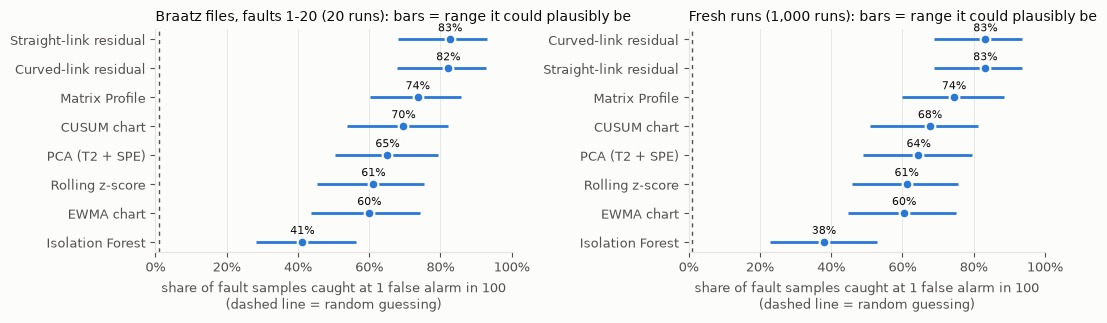

In [8]:
plots.pilot_overall({"a": rep[BRAATZ]["new"], "b": rep[FRESH]["new"]},
                    titles={"a": "Braatz files, faults 1-20 (20 runs)", "b": "Fresh runs (1,000 runs)"});

**The same table under the old rule**, for comparison with earlier notebooks. The straight-link detector reads the same (0.81, 0.83, 0.83, 0.83). The per-sensor charts and Isolation Forest read higher than they should.

In [9]:
pd.DataFrame({name: run.rates(r["old"]) for name, r in rep.items()}).loc[best_first]

,"Braatz files, 21 faults","Braatz files, faults 1-20","fresh runs, learning from 1 run","fresh runs, learning from 20 runs","fresh runs, other random numbers"
detector,,,,,
Curved-link residual,0.81 (0.68-0.92),0.83 (0.68-0.93),0.83 (0.68-0.93),0.83 (0.69-0.94),0.83 (0.83-0.83)
Straight-link residual,0.81 (0.68-0.92),0.83 (0.68-0.93),0.83 (0.68-0.93),0.83 (0.69-0.94),0.83 (0.83-0.83)
Matrix Profile,0.76 (0.61-0.89),0.77 (0.62-0.91),0.80 (0.67-0.91),0.75 (0.60-0.88),0.75 (0.74-0.75)
CUSUM chart,0.71 (0.58-0.85),0.71 (0.57-0.84),0.74 (0.61-0.85),0.76 (0.62-0.88),0.76 (0.74-0.79)
PCA (T2 + SPE),0.65 (0.51-0.79),0.66 (0.51-0.80),0.65 (0.50-0.79),0.65 (0.50-0.80),0.65 (0.64-0.65)
Rolling z-score,0.62 (0.47-0.77),0.63 (0.46-0.78),0.65 (0.50-0.79),0.66 (0.51-0.80),0.66 (0.65-0.67)
EWMA chart,0.61 (0.47-0.76),0.62 (0.46-0.77),0.65 (0.49-0.78),0.69 (0.54-0.81),0.69 (0.67-0.71)
Isolation Forest,0.41 (0.27-0.56),0.42 (0.27-0.57),0.46 (0.31-0.59),0.48 (0.34-0.61),0.48 (0.45-0.51)


**The gaps, measured.** Each row compares the straight-link residual detector with another detector under the new rule, as in `main.ipynb`. A positive gap means the straight-link detector catches more. It is called *ahead* only when the gap is at least 0.12 and its plausible range stays above zero; otherwise it is a *tie*.

In [10]:
others = ["Matrix Profile", "PCA (T2 + SPE)", "CUSUM chart", "Curved-link residual"]
for name in [BRAATZ, "fresh runs, learning from 1 run", FRESH, "fresh runs, other random numbers"]:
    print(name)
    display(run.gap_table(rep[name]["new"], "Straight-link residual", others))

Braatz files, faults 1-20


,gap,low,high,verdict
Straight-link residual against,,,,
Matrix Profile,0.091,0.028,0.153,tie
PCA (T2 + SPE),0.176,0.077,0.278,ahead
CUSUM chart,0.131,0.03,0.248,ahead
Curved-link residual,0.005,0.002,0.008,tie


fresh runs, learning from 1 run


,gap,low,high,verdict
Straight-link residual against,,,,
Matrix Profile,0.157,0.056,0.26,ahead
PCA (T2 + SPE),0.183,0.082,0.286,ahead
CUSUM chart,0.236,0.119,0.362,ahead
Curved-link residual,0.002,0.001,0.003,tie


fresh runs, learning from 20 runs


,gap,low,high,verdict
Straight-link residual against,,,,
Matrix Profile,0.088,0.014,0.166,tie
PCA (T2 + SPE),0.187,0.078,0.297,ahead
CUSUM chart,0.155,0.062,0.269,ahead
Curved-link residual,0,-0.001,0,tie


fresh runs, other random numbers


,gap,low,high,verdict
Straight-link residual against,,,,
Matrix Profile,0.088,0.086,0.09,tie
PCA (T2 + SPE),0.187,0.185,0.189,ahead
CUSUM chart,0.155,0.146,0.163,ahead
Curved-link residual,0,-0.001,0,tie


**Reading this**
- **Against Matrix Profile: a tie.** The straight-link detector is 9 points ahead on the Braatz files (range 3 to 15) and 9 points ahead on the fresh runs (range 1 to 17). That is under the 12-point margin, so we don't call it a win. The range stays above zero both times, so the straight-link detector is probably a little better.
- **With little normal data, it is a win.** When both learn from one run, the gap to Matrix Profile is 16 points (range 6 to 26).
- **Against PCA: ahead**, by 19 points on the fresh runs (range 8 to 30) and 18 on the Braatz files.
- **Against the CUSUM chart: ahead**, by 16 points on the fresh runs (range 6 to 27). Under the old rule this looked like a tie.
- **Against the curved-link detector: no difference at all.** The gap is 0.000. Curves add nothing on this plant, on fresh runs as on the Braatz files.
- The last table redraws run numbers instead of faults. The gap to Matrix Profile is then pinned down very tightly (0.086 to 0.090). So the gap is real but small. The 12-point margin protects against a different set of faults, not against different random numbers.

## 5. Excess alarms over the twin

The twins give a second, independent way to check a catch rate. For each faulty run, take the share of hours 8-48 above the alarm line, and subtract the share of the same hours above the line in its fault-free twin. What is left is what the fault itself added. We call it the **excess alarms over the twin**.

The twins played no part in setting the alarm lines (those came from runs 51-100). So their own alarm rate is also a test of the new rule: it should come out near 0.01.

Ranges redraw the faults, the run numbers and the fault-free runs that set the alarm lines.

In [11]:
twin = structure.cached("fresh_twin", lambda: run.excess_summary(fresh, twins))
twin.sort_values("excess alarms over the twin", ascending=False)

,alarms in fault runs,alarms in twins,"twins, low","twins, high",excess alarms over the twin,low,high
detector,,,,,,,
Straight-link residual,0.832,0.008,0.007,0.01,0.824,0.683,0.933
Curved-link residual,0.832,0.009,0.007,0.011,0.823,0.683,0.932
Matrix Profile,0.744,0.008,0.006,0.01,0.736,0.586,0.873
CUSUM chart,0.677,0.011,0.003,0.022,0.666,0.513,0.812
PCA (T2 + SPE),0.645,0.009,0.008,0.011,0.635,0.489,0.777
Rolling z-score,0.611,0.011,0.005,0.017,0.601,0.453,0.75
EWMA chart,0.604,0.011,0.006,0.019,0.593,0.441,0.746
Isolation Forest,0.378,0.009,0.005,0.014,0.369,0.222,0.531


**Reading this**
- **The new alarm lines do what they promise.** In the twins, where nothing is wrong, every detector raises alarms in about 1 reading in 100 (between 0.008 and 0.011).
- **So the excess is the catch rate minus about one point**: 0.82 for the straight-link detector (range 0.68 to 0.93), 0.74 for Matrix Profile, 0.67 for the CUSUM chart, 0.63 for PCA.
- Under the old rule this subtraction would have taken 18 points off the CUSUM chart. Under the new rule there is almost nothing left to take off.

## 6. Fault 3 and the CUSUM chart

Fault 3 is a step change in the temperature of one feed stream. On the one Braatz run the CUSUM chart flagged 40% of it, and every other detector under 5%. The table shows the CUSUM chart on the 50 fresh runs of fault 3 and on their twins.

In [12]:
FAULT_3 = "03 step: D feed temperature"
cusum = structure.cached("fresh_cusum", lambda: run.excess_over_twin(fresh, twins, "cusum"))
display(cusum.loc[[FAULT_3]])
braatz = rep["Braatz files, 21 faults"]
print(f"Old alarm line: CUSUM flagged {run.by_fault(rep[FRESH]['old'], 'CUSUM chart')[FAULT_3]:.2f} of fault 3 on the fresh runs "
      f"and {run.by_fault(braatz['old'], 'CUSUM chart')[FAULT_3]:.2f} on the one Braatz run.")
print(f"New alarm line on the one Braatz run (line set on a single fault-free run): "
      f"{run.by_fault(braatz['new'], 'CUSUM chart')[FAULT_3]:.2f}.")
per_run = run.per_run_rates(fresh, "cusum", FAULT_3)
print(f"Single runs of fault 3, new line: lowest {per_run.min():.2f}, middle {per_run.median():.2f}, "
      f"highest {per_run.max():.2f}. {(per_run >= 0.40).sum()} of {len(per_run)} runs reach 0.40 or more.")

,alarms in fault runs,alarms in twins,excess alarms over the twin,low,high
kind of fault,,,,,
03 step: D feed temperature,0.011,0.011,0,-0.001,0


Old alarm line: CUSUM flagged 0.20 of fault 3 on the fresh runs and 0.40 on the one Braatz run.
New alarm line on the one Braatz run (line set on a single fault-free run): 0.30.


Single runs of fault 3, new line: lowest 0.00, middle 0.00, highest 0.08. 0 of 50 runs reach 0.40 or more.


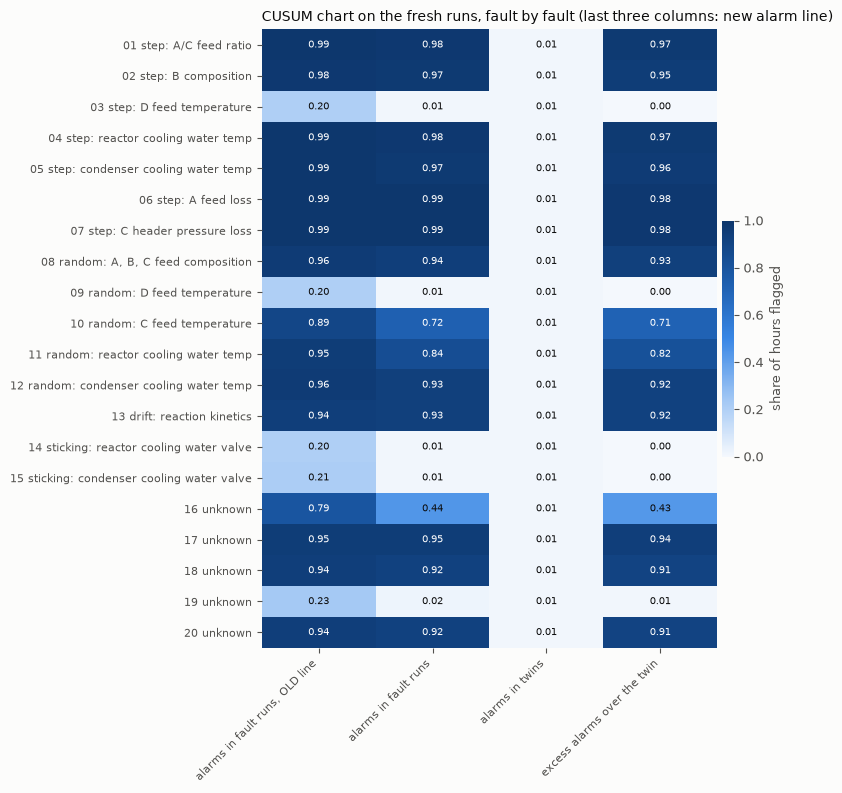

In [13]:
grid = cusum.assign(**{"alarms in fault runs, OLD line": run.by_fault(rep[FRESH]["old"], "CUSUM chart")})
grid = grid[["alarms in fault runs, OLD line", "alarms in fault runs", "alarms in twins", "excess alarms over the twin"]]
plots.heatmap(grid.round(2) + 0.0, vmax=1, fmt="{:.2f}", figsize=(8, 8), colorbar_label="share of hours flagged",
              title="CUSUM chart on the fresh runs, fault by fault (last three columns: new alarm line)");

**Reading this**
- **The CUSUM chart does not detect fault 3.** Under the new rule it flags 0.011 of fault 3's hours, and 0.011 of the same hours in the twins, where there is no fault. The excess is 0.000 (range -0.001 to 0.000). No single run of fault 3 gets above 0.08.
- **The 40% was the old alarm line plus one lucky run.** Under the old line the CUSUM chart flags 0.20 of fault 3 on the fresh runs, which is just its general ringing in hours 8-48. The one Braatz run happened to sit at twice that.
- **The Braatz files alone cannot settle this.** Even under the new rule the one Braatz run still shows 0.30, because its alarm line comes from a single fault-free run. The CUSUM chart's score climbs very differently from one healthy run to the next, so one run is not enough to place its line. Treat CUSUM numbers from the Braatz files with caution.
- **The same holds for faults 9, 14 and 15**: the CUSUM chart's excess is 0.00. For fault 19 it is 0.011 (range 0.004 to 0.017): real, but far too small to be useful.

## 7. What kind of fault is each fault, recounted

`02_how_curved.ipynb` sorted the 21 Braatz faults into four kinds, using the old rule: 9 *single sensor*, 7 *many sensors*, 2 *hidden from level checks* and 3 *hard for all*. A fault counts as caught by "level checks" when the best of the three per-sensor charts (rolling z-score, EWMA, CUSUM) catches at least half of it. Those are the detectors the old rule flattered, so the sorting is redone here.

The table counts the kinds under each rule, for the Braatz files and for the fresh runs. It is built from the saved scores, so nothing is fitted again.

In [14]:
kinds = structure.cached("fresh_kinds", lambda: {
    "Braatz files, old line": structure.fault_types(tep, saved=True, calibration="pooled"),
    "Braatz files, new line": structure.fault_types(tep, saved=True),
    "fresh runs, old line": structure.fault_types(fresh, saved=True, calibration="pooled"),
    "fresh runs, new line": structure.fault_types(fresh, saved=True),
})
order = ["single sensor", "many sensors", "hidden from level checks", "hard for all"]
pd.DataFrame({name: t["kind"].value_counts() for name, t in kinds.items()}).reindex(order).fillna(0).astype(int)

,"Braatz files, old line","Braatz files, new line","fresh runs, old line","fresh runs, new line"
kind,,,,
single sensor,9,9,8,7
many sensors,7,7,7,7
hidden from level checks,2,2,2,3
hard for all,3,3,3,3


In [15]:
display(pd.DataFrame({name: t["kind"] for name, t in kinds.items()}).fillna("(not in these files)"))
kinds["fresh runs, new line"]

,"Braatz files, old line","Braatz files, new line","fresh runs, old line","fresh runs, new line"
kind of fault,,,,
01 step: A/C feed ratio,many sensors,many sensors,many sensors,many sensors
02 step: B composition,many sensors,many sensors,many sensors,many sensors
03 step: D feed temperature,hard for all,hard for all,hard for all,hard for all
04 step: reactor cooling water temp,single sensor,single sensor,single sensor,single sensor
05 step: condenser cooling water temp,single sensor,single sensor,single sensor,single sensor
06 step: A feed loss,many sensors,many sensors,many sensors,many sensors
07 step: C header pressure loss,single sensor,single sensor,single sensor,single sensor
"08 random: A, B, C feed composition",many sensors,many sensors,many sensors,many sensors
09 random: D feed temperature,hard for all,hard for all,hard for all,hard for all


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
01 step: A/C feed ratio,0.993,0.997,0.997,0.992,9,many sensors
02 step: B composition,0.984,0.988,0.988,0.984,17,many sensors
03 step: D feed temperature,0.011,0.011,0.012,0.008,0,hard for all
04 step: reactor cooling water temp,0.998,1,1,1,1,single sensor
05 step: condenser cooling water temp,0.974,1,1,0.992,1,single sensor
06 step: A feed loss,0.999,1,1,1,35.1,many sensors
07 step: C header pressure loss,0.999,1,1,1,1,single sensor
"08 random: A, B, C feed composition",0.966,0.973,0.973,0.965,30.7,many sensors
09 random: D feed temperature,0.012,0.014,0.014,0.009,0,hard for all


**Reading this**
- **Braatz files:** the old rule gives 9 / 7 / 2 / 3, the same as `02_how_curved.ipynb`. The new rule gives the same counts. No fault changes its label, although several level-check numbers fall (fault 16 from 0.73 to 0.68, fault 21 from 0.75 to 0.68).
- **Fresh runs, new rule: 7 / 7 / 3 / 3** over 20 faults. That is two fewer single-sensor faults than 9, for two different reasons:
  - Fault 21 was a single-sensor fault, and it is not in the fresh files.
  - **Fault 16 moves from *single sensor* to *hidden from level checks*.** Level checks caught 0.79 of it under the old rule and catch 0.44 under the new one. Link checks catch 0.97.
- **The old rule made level checks look as if they saw a little of everything.** On the fresh runs they seemed to catch 0.20 of faults 3, 9 and 15, and 0.42 of fault 14. Under the new rule those are 0.01, 0.01, 0.01 and 0.19.
- **The three hard faults stay hard.** Nothing here catches more than 3% of faults 3, 9 or 15.
- **Still no fault needs curves.** The curved-link column never beats the straight-link column.

`02_how_curved.ipynb` has not been changed. Its Tennessee Eastman level-check numbers, and its "CUSUM catches 40% of fault 3", used the old rule. Its counts of the four kinds stand.

## 8. Fault by fault

The grid shows each detector's catch rate on each fault, on the fresh runs under the new rule. The table after it shows the straight-link detector fault by fault, with its excess alarms over the twin and their plausible range, next to its catch rate on the single Braatz run of the same fault.

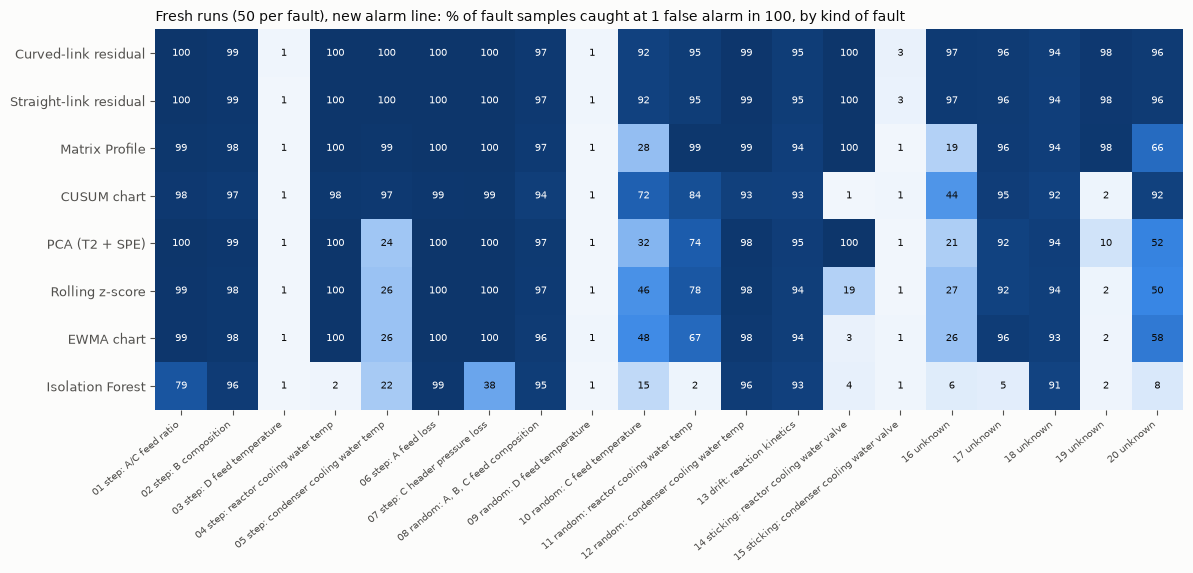

In [16]:
plots.pilot_by_type({"fresh": rep[FRESH]["new"]}, titles={"fresh": "Fresh runs (50 per fault), new alarm line"});

In [17]:
link = structure.cached("fresh_link", lambda: run.excess_over_twin(fresh, twins, "link_straight"))
link.assign(**{"Braatz file (one run)": run.by_fault(rep[BRAATZ]["new"], "Straight-link residual")})

,alarms in fault runs,alarms in twins,excess alarms over the twin,low,high,Braatz file (one run)
kind of fault,,,,,,
01 step: A/C feed ratio,0.997,0.008,0.989,0.987,0.99,0.998
02 step: B composition,0.988,0.008,0.98,0.978,0.981,0.988
03 step: D feed temperature,0.011,0.008,0.003,0.002,0.003,0.011
04 step: reactor cooling water temp,1,0.008,0.992,0.99,0.993,1
05 step: condenser cooling water temp,1,0.008,0.992,0.99,0.993,1
06 step: A feed loss,1,0.008,0.992,0.99,0.993,1
07 step: C header pressure loss,1,0.008,0.992,0.99,0.993,1
"08 random: A, B, C feed composition",0.973,0.008,0.965,0.962,0.968,0.978
09 random: D feed temperature,0.014,0.008,0.005,0.004,0.007,0.019


**Reading this**
- **The straight-link detector catches at least 0.92 of 17 of the 20 faults.** The other three are faults 3, 9 and 15, where it catches between 1% and 3%.
- **It agrees with the single Braatz runs** fault by fault, to within a few points.
- **Where Matrix Profile falls behind:** faults 10 (0.28 against 0.92), 16 (0.19 against 0.97) and 20 (0.66 against 0.96). Those three faults make up most of the 9-point gap. Matrix Profile is slightly ahead on fault 11 (0.99 against 0.95).
- **Where PCA falls behind:** faults 5, 10, 16, 19 and 20. Both PCA and the straight-link detector use straight-line links, so how the links are used matters, not only whether a method can use them.

## 9. What this means

**The two questions**
1. **Does the straight-link residual detector hold its 0.81? Yes.** It catches 0.83 of fault moments on 1,000 fresh runs (plausible range 0.69 to 0.94), against 0.83 on the Braatz files for the same 20 faults. It does not matter which rule sets the alarm line, or whether the detector learns from one run or twenty.
2. **Does the CUSUM chart catch 40% of fault 3? No.** On 50 fresh runs it flags the same 1% of fault 3 as of the fault-free twins. The 40% came from an alarm line that was too low and one lucky run.

**What changed along the way**
- **The alarm line is now set on healthy readings from the same hours the faults occupy.** A line set on the first 8 hours let the per-sensor charts ring far too often later in a run, and counted that ringing as detection. This applies to the Tennessee Eastman numbers in `main.ipynb` too.
- **Where the detectors stand under the new rule, on the fresh runs:** straight-link residual 0.83, curved-link residual 0.83, Matrix Profile 0.74, CUSUM 0.68, PCA 0.64, rolling z-score 0.61, EWMA 0.60, Isolation Forest 0.38.
- **Under the 12-point rule:** the straight-link detector and Matrix Profile tie (gap 0.09). The straight-link detector is ahead of PCA (0.19), the CUSUM chart (0.16) and the other per-sensor checks. Curves add nothing (gap 0.000).
- **The bar for deep learning on this plant is therefore 0.83**, and to count as a win a deep model has to reach about 0.95.

**What was decided when**
- Detector settings: unchanged from `main.ipynb`.
- Which runs to use: fixed by run number before any scoring.
- The twins: found in the data before any scoring.
- The two kinds of plausible range: chosen before looking at results.
- The new alarm-line rule: adopted **after** seeing the false alarms in section 3. Both rules are shown everywhere so the effect can be judged.
- Two changes to the code that do not change any earlier number: Matrix Profile now finds its distances with a faster calculation (the same distances to 12 digits; the original would have taken over two hours here), and the curved-link model no longer uses a random hold-out on large data.

**Limits**
- This is still a simulated plant, and the same simulator as before.
- The fresh files have 20 of the 21 faults, and we used 50 of the 500 runs per fault.
- For the Braatz files, the new alarm lines rest on a single fault-free run of 800 readings. Their ranges do not include how uncertain those lines are.
- Both datasets still have straight links. None of this tests whether deep learning helps when links are curved.